In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
from pipeline.notebook_utils import (
    carregar_noaa_por_tipo,
    identificar_porcoes_ativas,
    processar_ou_carregar_porcao,
    media_por_sink_raio,
    ajustar_lei_potencia,
    plotar_lei_potencia,
    plotar_varredura_4_tipos_r1_a_22km,
)

tipos_noaa = carregar_noaa_por_tipo()
for nome, df_t in tipos_noaa.items():
    print(f"{nome:16s}: {len(df_t):5d} pontos")

Ocean water     : 14363 pontos
Ocean sediment  :   319 pontos
Nurdle Patrol   : 10615 pontos
Beach           :   893 pontos


In [2]:
info, arr, label, porcoes_ativas = identificar_porcoes_ativas(tipos_noaa["Ocean water"], max_r_km=50.0)

bacias_por_porcao = [processar_ou_carregar_porcao(v, info, arr, label) for v in porcoes_ativas]
df_bacias_globais = pd.concat([d for d in bacias_por_porcao if len(d) > 0], ignore_index=True)
print(f"Porcoes ativas: {len(porcoes_ativas)} | Total de bacias (100% sem corte): {len(df_bacias_globais)}")

Porcoes ativas: 1061 | Total de bacias (100% sem corte): 179718


In [3]:
pareados_tipos_r = {nome: {} for nome in tipos_noaa}
linhas_tipos = []

for nome, pts_df in tipos_noaa.items():
    for r_km in range(1, 23):
        df_r = media_por_sink_raio(df_bacias_globais, pts_df, r_km=r_km)
        pareados_tipos_r[nome][r_km] = df_r
        c_u = ajustar_lei_potencia(df_r, "urban_population", "mp_mean")
        f_t = ajustar_lei_potencia(df_r, "total_population", "flux")
        linhas_tipos.append({
            "Tipo_NOAA": nome,
            "R_km": r_km,
            "N_urb": c_u["N"],
            "beta_Conc_Urb": c_u["beta"],
            "R2_Conc_Urb_pct": c_u["r2_pct"],
            "N_tot": f_t["N"],
            "beta_Fluxo_Tot": f_t["beta"],
            "R2_Fluxo_Tot_pct": f_t["r2_pct"],
        })

df_var_tipos = pd.DataFrame(linhas_tipos)
print(df_var_tipos[df_var_tipos["R_km"].isin([5, 10, 13, 18, 22])].round(2).to_string(index=False))

     Tipo_NOAA  R_km  N_urb  beta_Conc_Urb  R2_Conc_Urb_pct  N_tot  beta_Fluxo_Tot  R2_Fluxo_Tot_pct
   Ocean water     5    254           0.49            10.62    754            0.56             26.05
   Ocean water    10    701           0.43             8.53   2763            0.52             25.65
   Ocean water    13    991           0.37             6.69   4159            0.50             24.29
   Ocean water    18   1439           0.30             4.33   6652            0.48             25.10
   Ocean water    22   1753           0.29             3.78   8714            0.47             24.67
Ocean sediment     5     38           0.61            67.00     83            0.59             34.63
Ocean sediment    10     89           0.52            37.88    245            0.63             40.22
Ocean sediment    13    135           0.44            27.37    343            0.62             40.63
Ocean sediment    18    190           0.35            19.71    486            0.60         

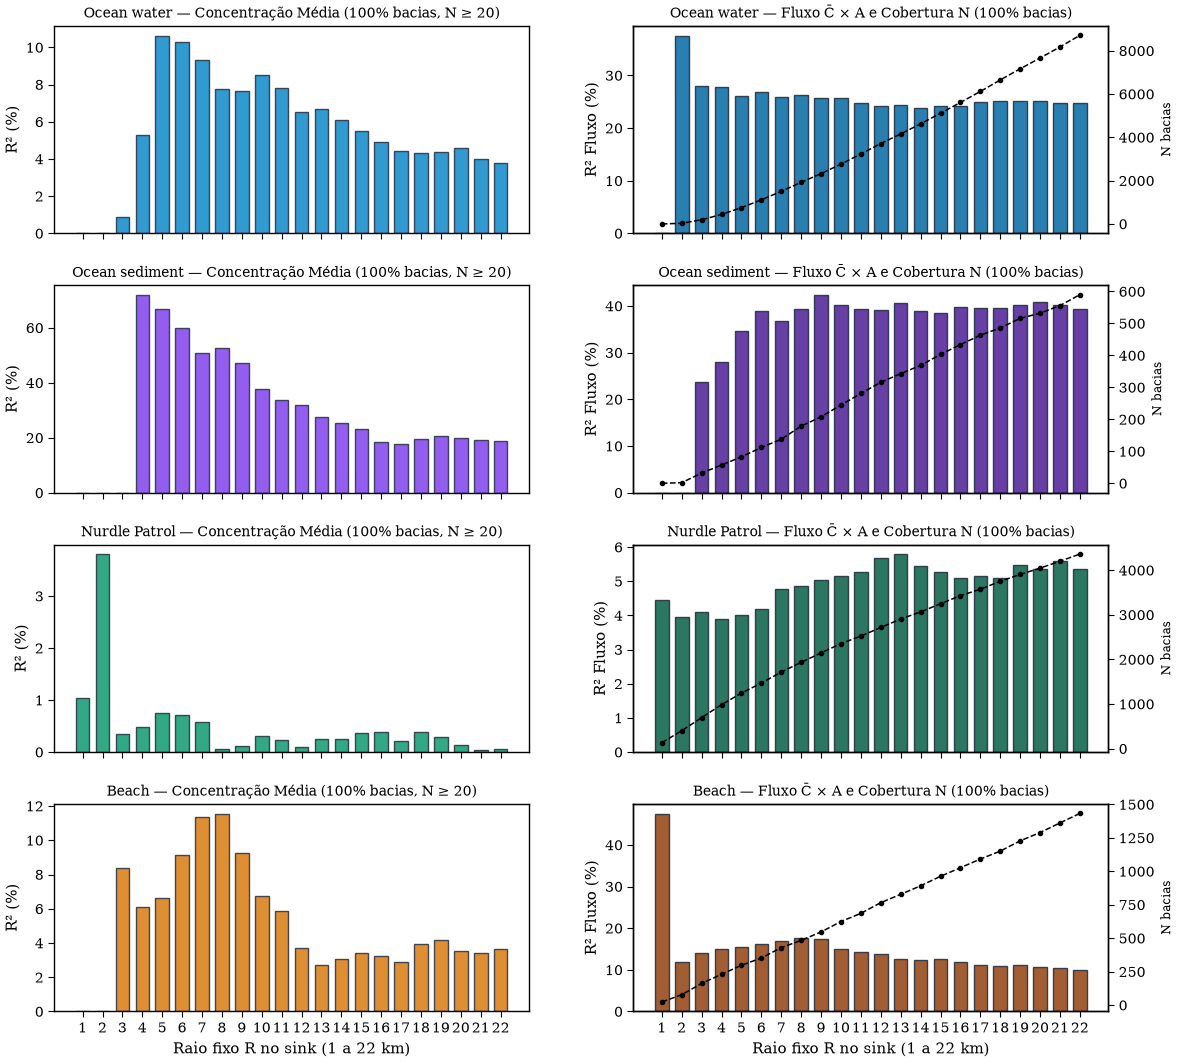

In [4]:
plotar_varredura_4_tipos_r1_a_22km(df_var_tipos)

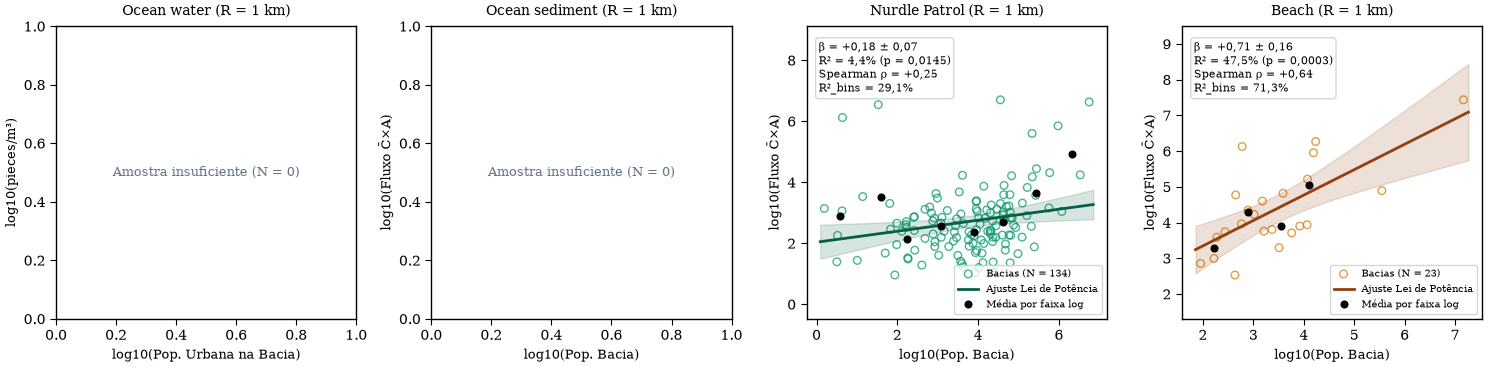

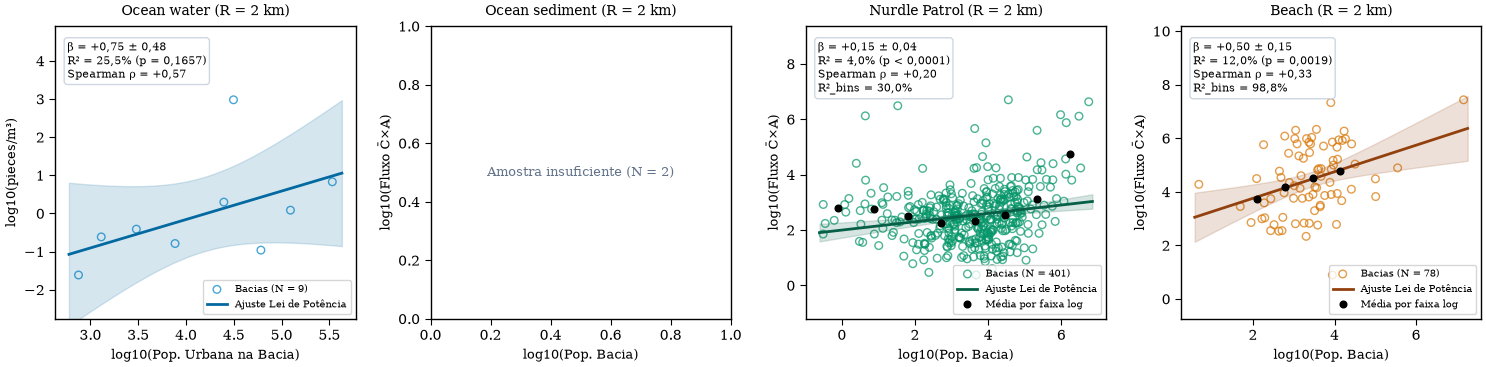

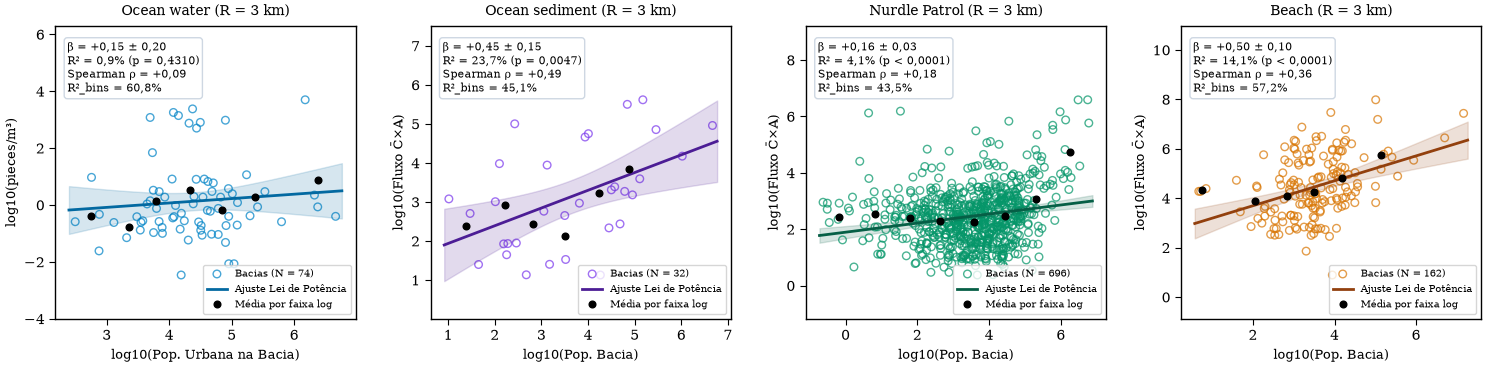

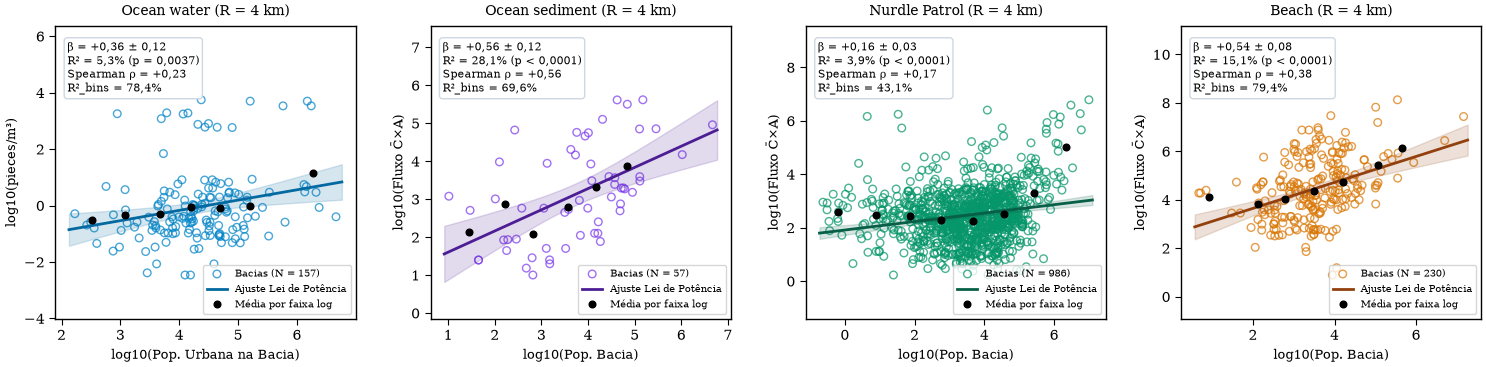

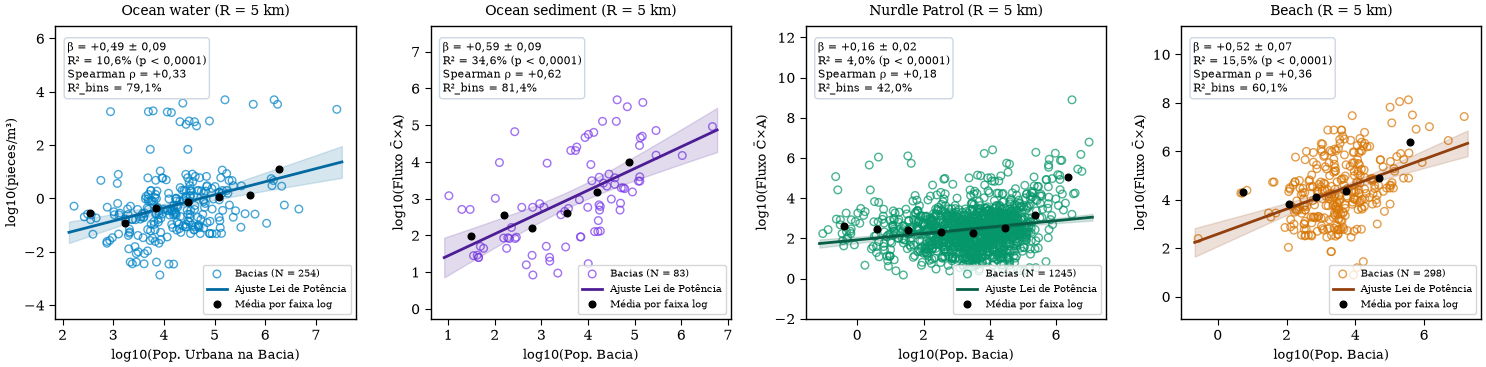

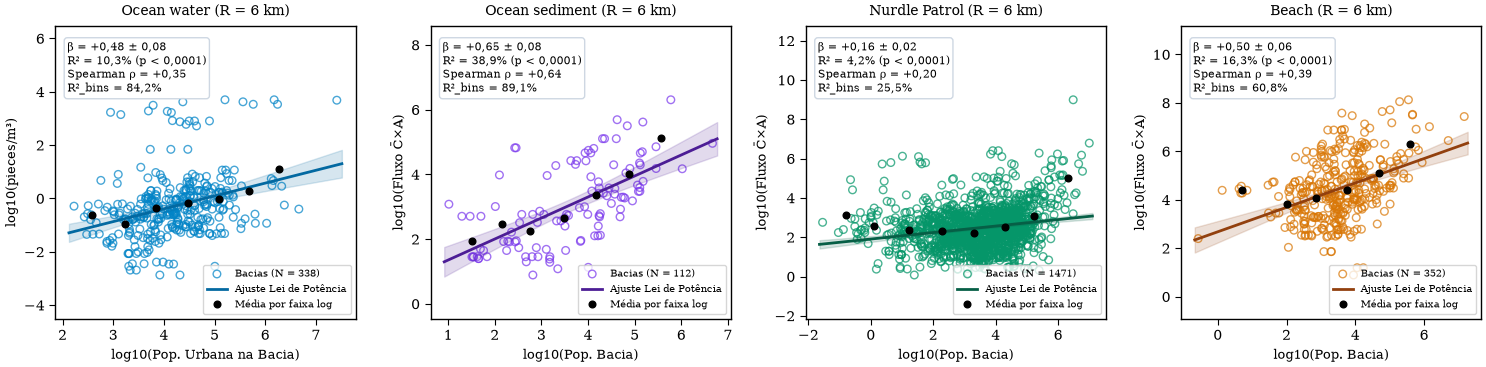

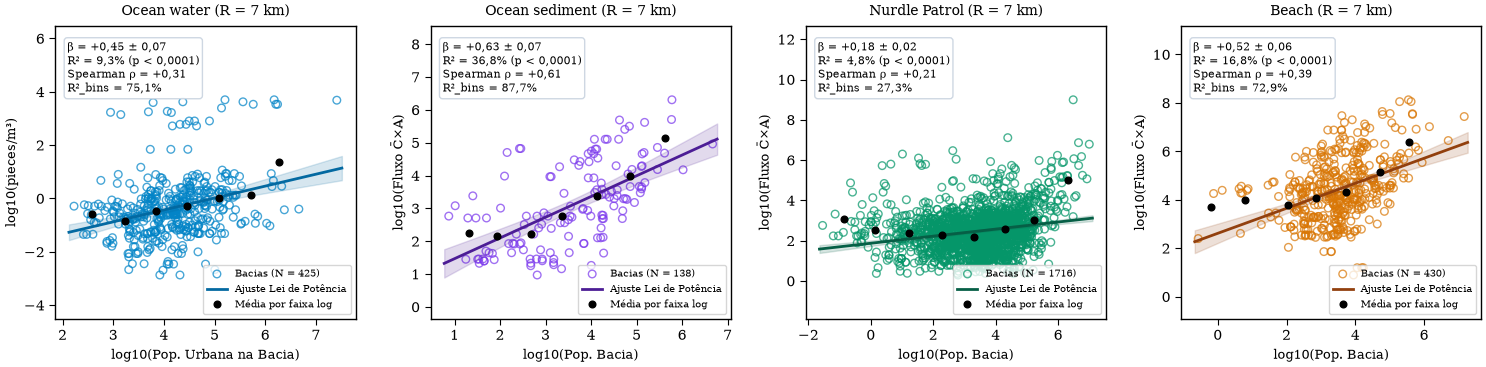

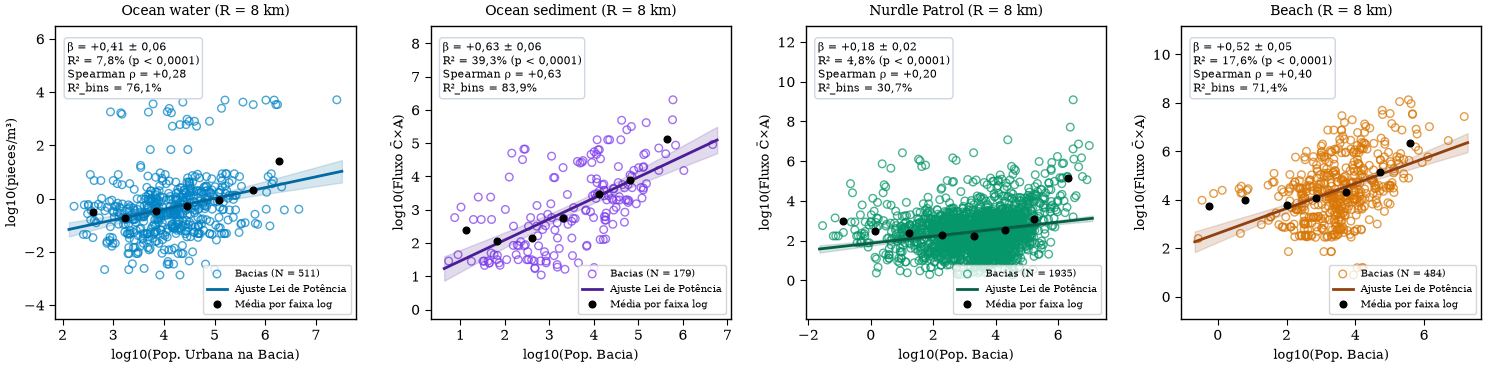

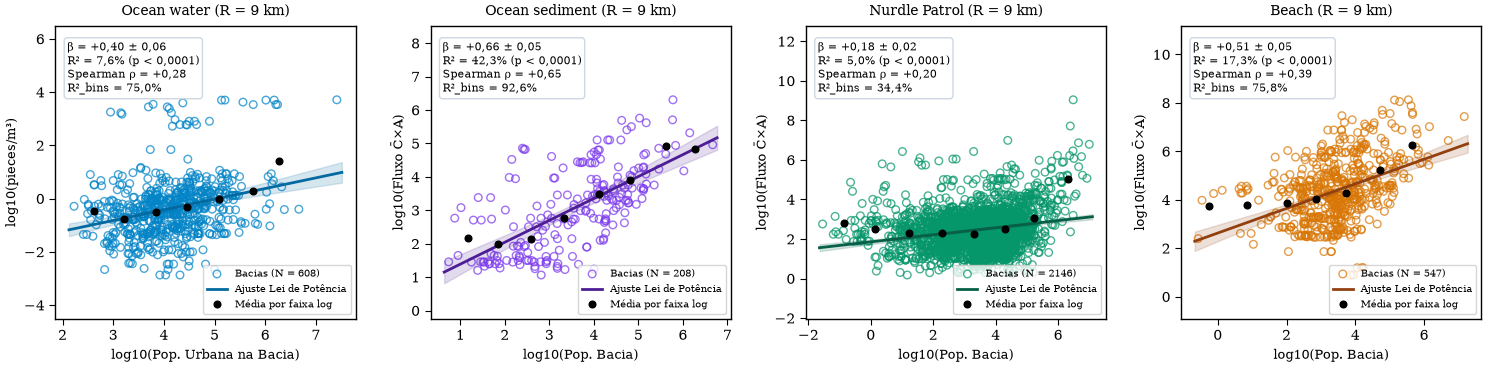

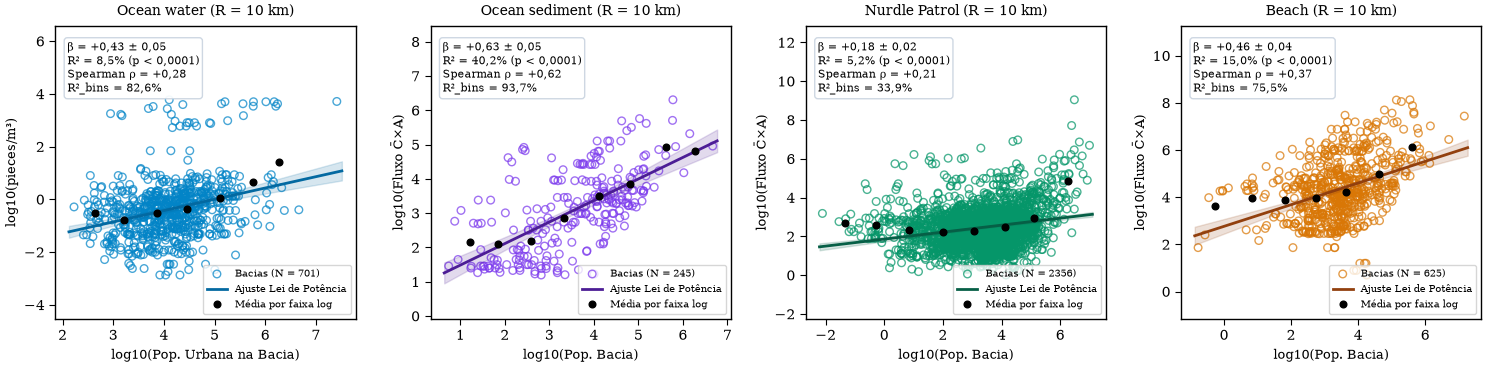

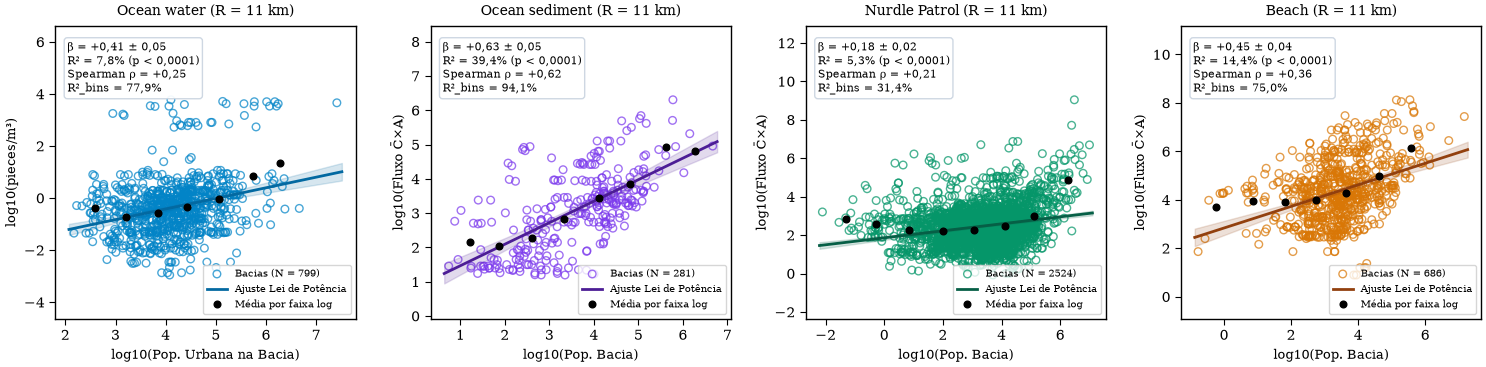

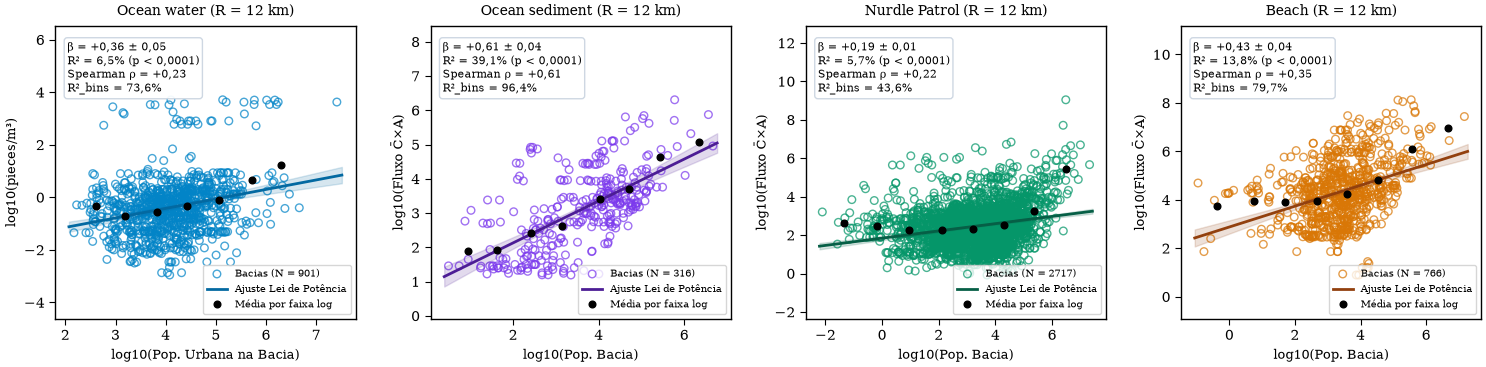

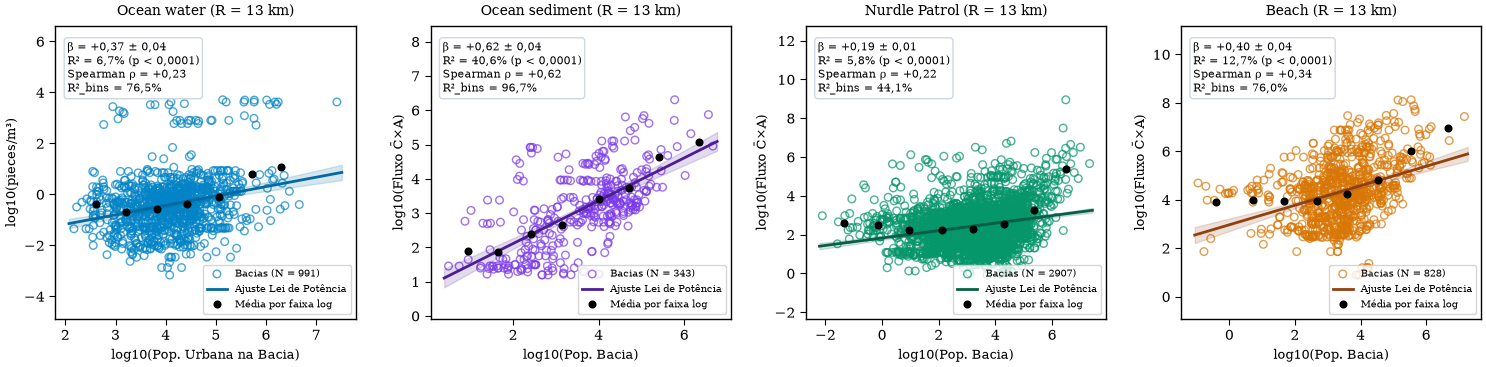

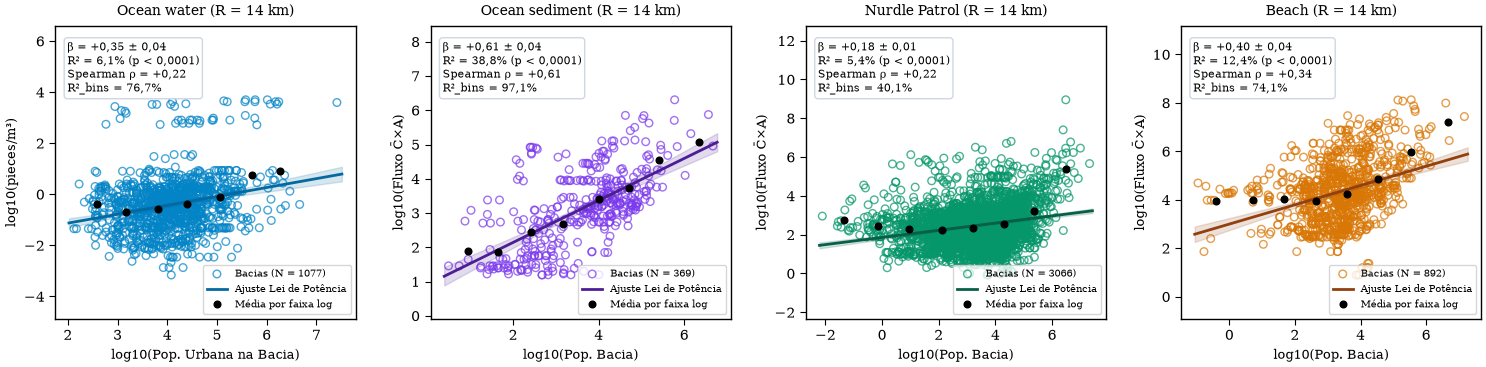

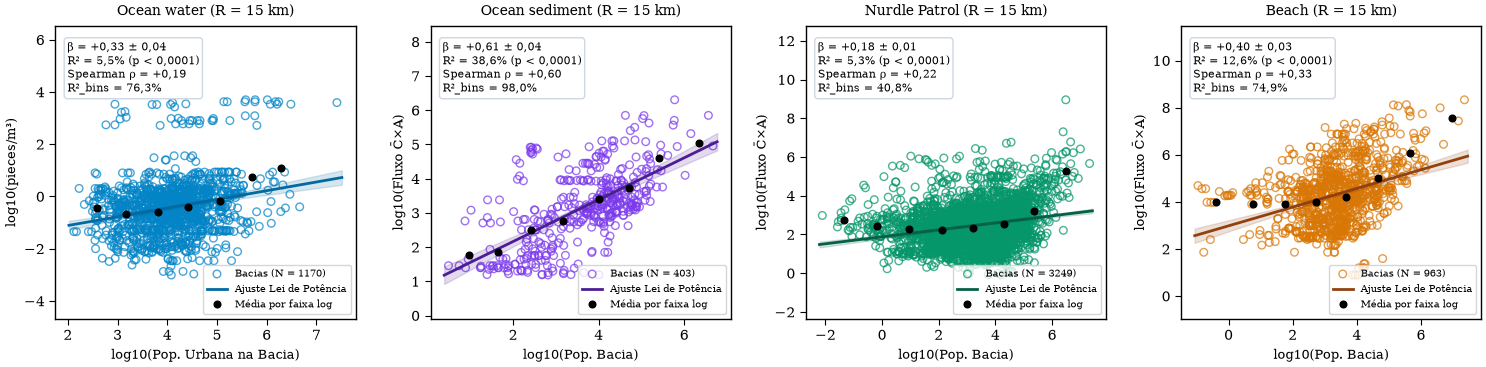

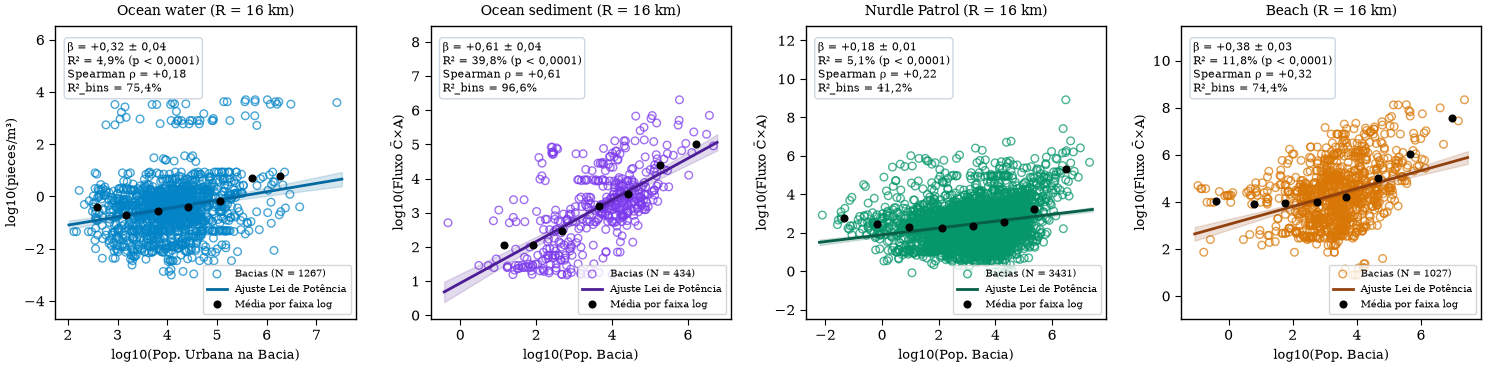

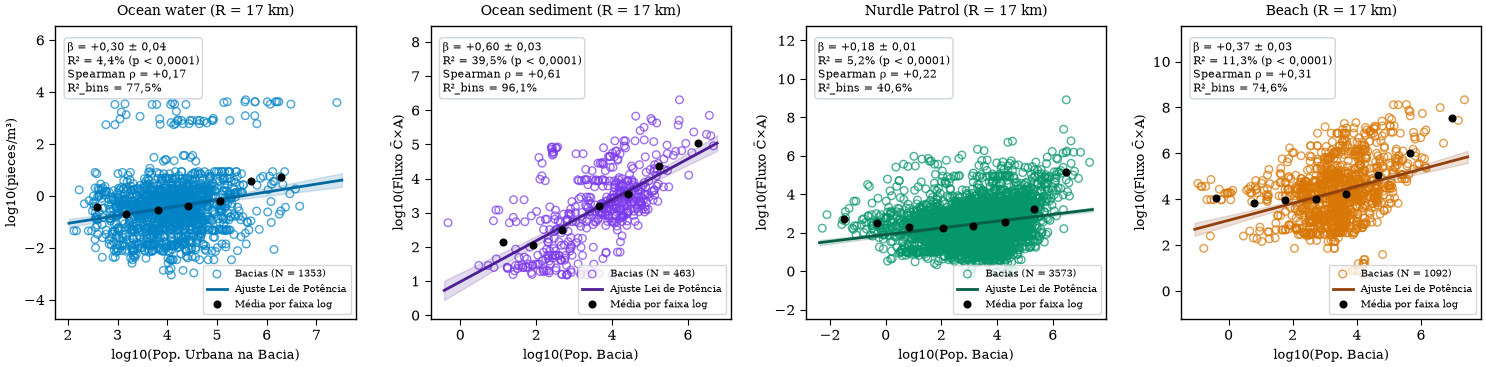

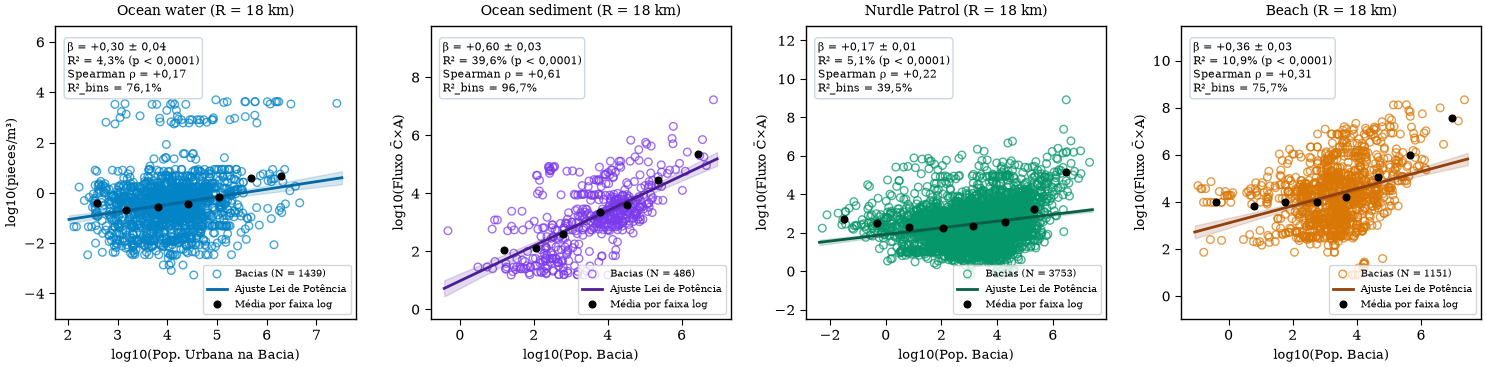

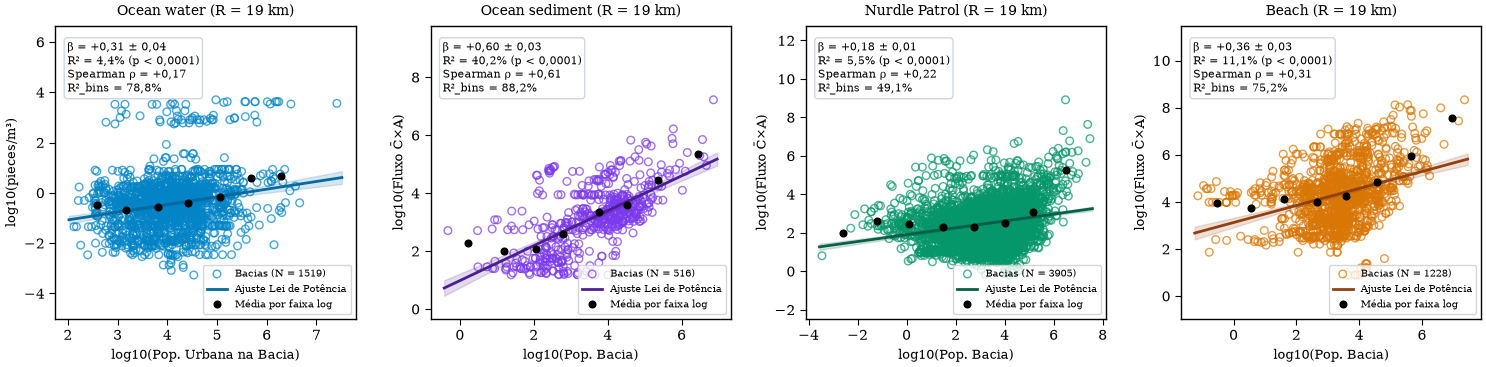

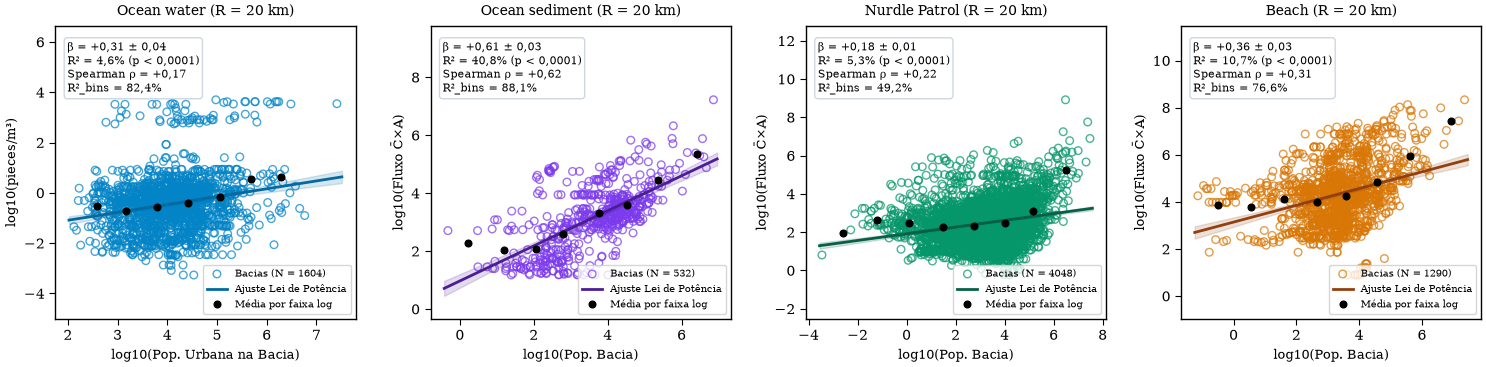

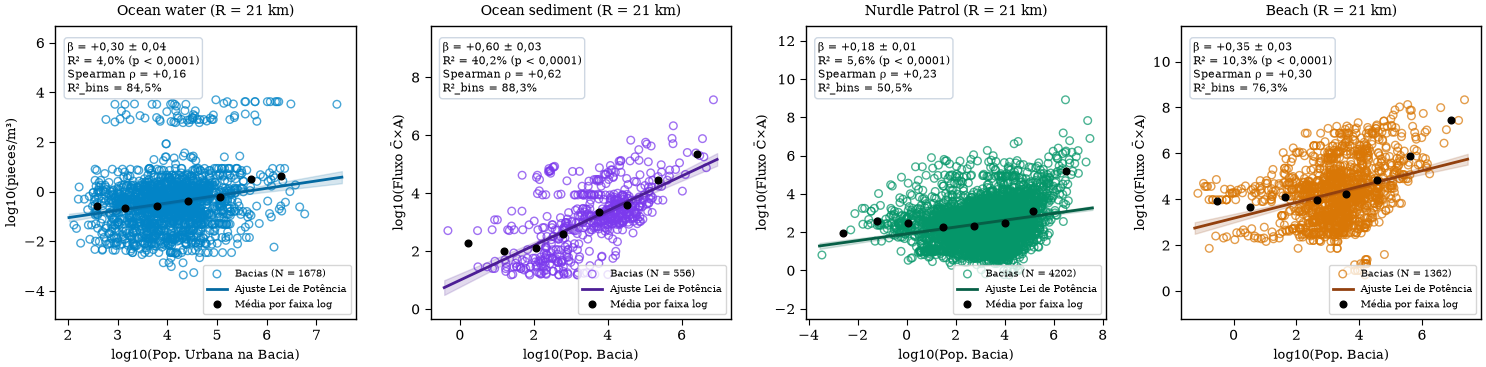

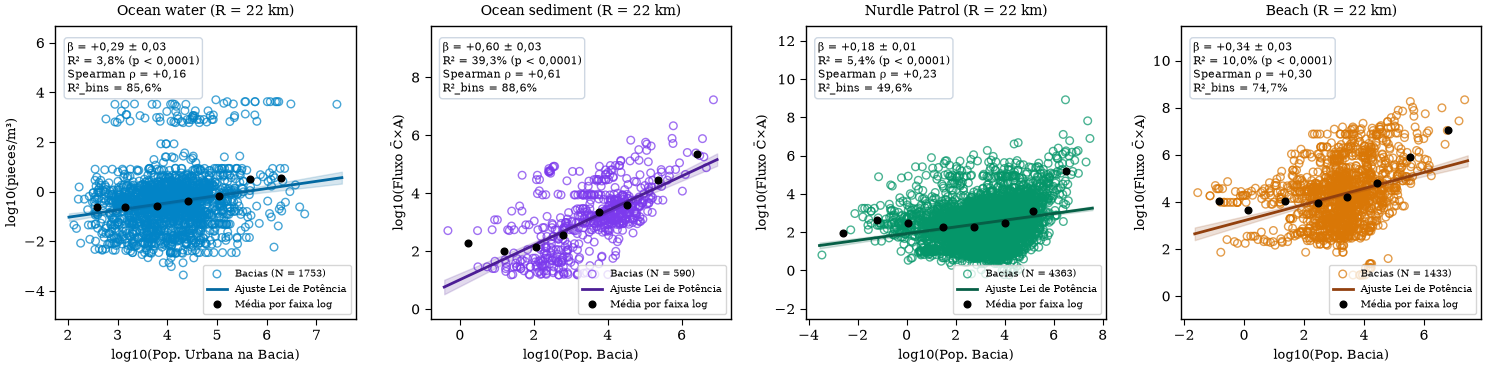

In [5]:
configs = [
    ("Ocean water", "urban_population", "mp_mean", "log10(Pop. Urbana na Bacia)", "log10(pieces/m³)", "#0284c7", "#0369a1"),
    ("Ocean sediment", "total_population", "flux", "log10(Pop. Bacia)", "log10(Fluxo C̄×A)", "#7c3aed", "#4c1d95"),
    ("Nurdle Patrol", "total_population", "flux", "log10(Pop. Bacia)", "log10(Fluxo C̄×A)", "#059669", "#065f46"),
    ("Beach", "total_population", "flux", "log10(Pop. Bacia)", "log10(Fluxo C̄×A)", "#d97706", "#92400e"),
]

for r_km in range(1, 23):
    fig, axes = plt.subplots(1, 4, figsize=(18.4, 3.8), gridspec_kw={"wspace": 0.25})
    for ax, (nome, p_col, y_col, xl, yl, c_pt, c_ln) in zip(axes, configs):
        plotar_lei_potencia(ax, pareados_tipos_r[nome][r_km], p_col, y_col, f"{nome} (R = {r_km} km)", xl, yl, c_pt, c_ln)
    plt.show()